<!-- # Machine Learning Revision & Practical
## Diamonds Dataset — EDA, Visualization & ML Algorithms -->

# Machine Learning Revision & Practical
## Diamonds Dataset — EDA, Visualization & ML Algorithms

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Train-Test Split
from sklearn.model_selection import train_test_split

# Feature Scaling
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Regression
from sklearn.linear_model import LinearRegression

# Classification
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# Clustering
from sklearn.cluster import KMeans, AgglomerativeClustering

# Model Evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [3]:
df = pd.read_csv('diamonds.csv')

In [4]:
df.head()

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [5]:
df.shape

(53940, 11)

In [6]:
df.columns

Index(['Unnamed: 0', 'carat', 'cut', 'color', 'clarity', 'depth', 'table',
       'price', 'x', 'y', 'z'],
      dtype='str')

In [7]:
df.info()             

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  53940 non-null  int64  
 1   carat       53940 non-null  float64
 2   cut         53940 non-null  str    
 3   color       53940 non-null  str    
 4   clarity     53940 non-null  str    
 5   depth       53940 non-null  float64
 6   table       53940 non-null  float64
 7   price       53940 non-null  int64  
 8   x           53940 non-null  float64
 9   y           53940 non-null  float64
 10  z           53940 non-null  float64
dtypes: float64(6), int64(2), str(3)
memory usage: 4.5 MB


In [8]:
df.isnull().sum()

Unnamed: 0    0
carat         0
cut           0
color         0
clarity       0
depth         0
table         0
price         0
x             0
y             0
z             0
dtype: int64

In [9]:
df.describe()     #numerical values ka statistical summary

,Unnamed: 0,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,26970.500000,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,15571.281097,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,1.000000,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,13485.750000,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,26970.500000,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,40455.250000,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,53940.000000,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.dtypes

Unnamed: 0      int64
carat         float64
cut               str
color             str
clarity           str
depth         float64
table         float64
price           int64
x             float64
y             float64
z             float64
dtype: object

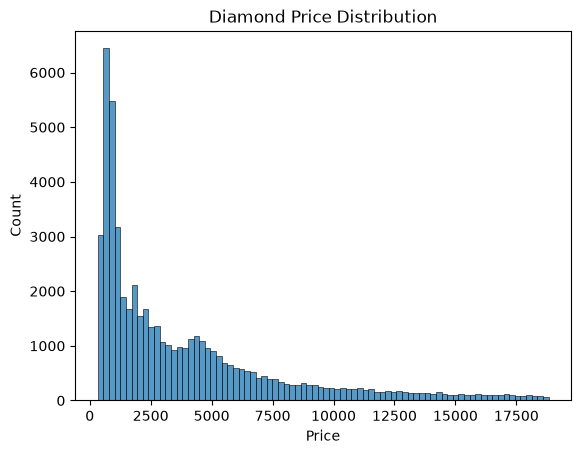

In [12]:
sns.histplot(data=df, x='price')
plt.title('Diamond Price Distribution')
plt.xlabel('Price')
plt.ylabel('Count')
plt.show()

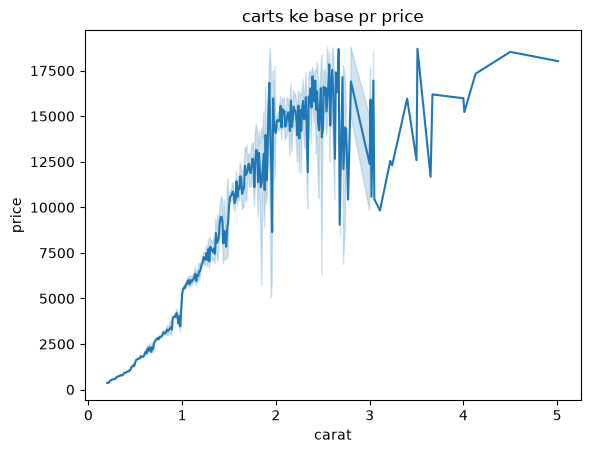

In [ ]:
df = df.sort_values(by = 'carat',ascending=True)

sns.lineplot(data = df,x = 'carat', y = 'price')
plt.title('carts ke base pr price')
plt.xlabel('carat')
plt.ylabel('price')
plt.show()

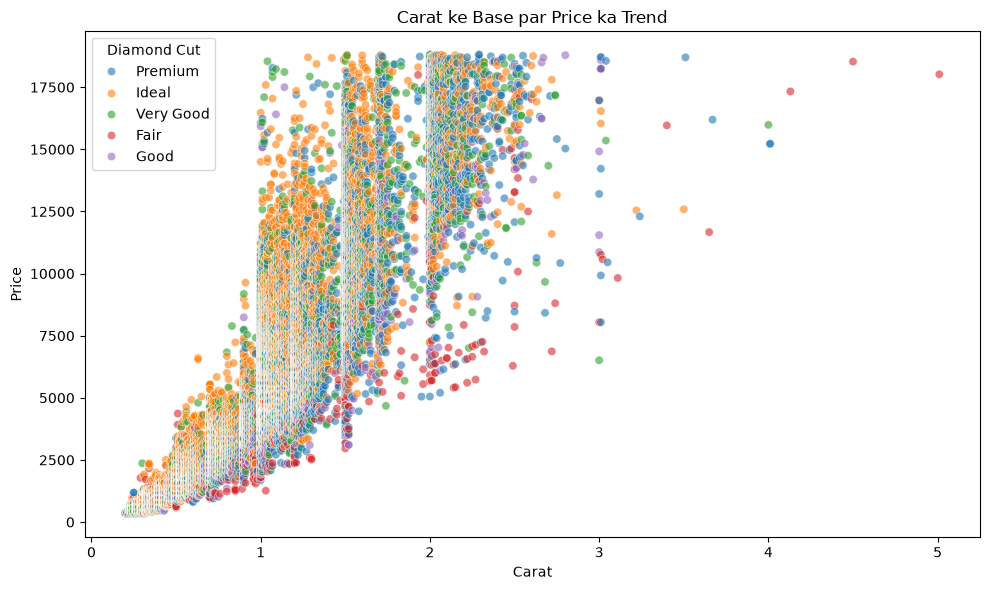

In [33]:

# Graph ka size set kar rahe hain
plt.figure(figsize=(10, 6))

# Carat aur price ka scatterplot bana rahe hain
# hue='cut' se har cut ko alag colour milega
# alpha se dots ki transparency set hoti hai
sns.scatterplot(data=df, x='carat', y='price', hue='cut', alpha=0.6)

# Graph ka title set kar rahe hain
plt.title('Carat ke Base par Price ka Trend')

# X-axis aur Y-axis ke labels set kar rahe hain
plt.xlabel('Carat')
plt.ylabel('Price')

# Legend ka title set kar rahe hain
plt.legend(title='Diamond Cut')

# Graph ki spacing ko adjust kar rahe hain
plt.tight_layout()

# Graph display kar rahe hain
plt.show()


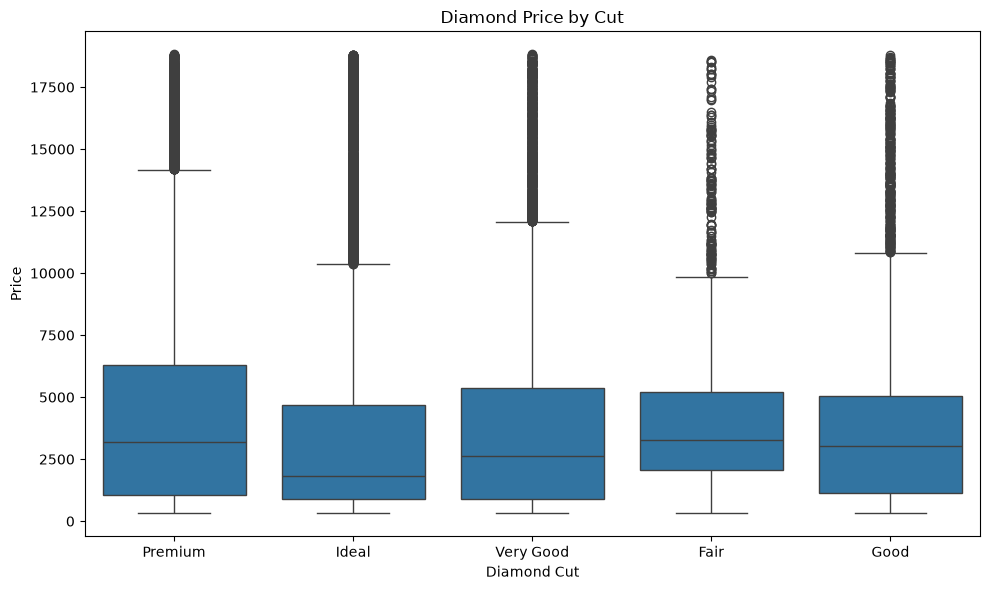

In [36]:

# Graph ka size set kar rahe hain
plt.figure(figsize=(10, 6))

# Cut ke hisaab se diamond prices ka boxplot bana rahe hain
sns.boxplot(data=df, x='cut', y='price')

# Graph ka title set kar rahe hain
plt.title('Diamond Price by Cut')

# X-axis aur Y-axis ke labels set kar rahe hain
plt.xlabel('Diamond Cut')
plt.ylabel('Price')

# Graph ki spacing adjust kar rahe hain
plt.tight_layout()

# Graph display kar rahe hain
plt.show()


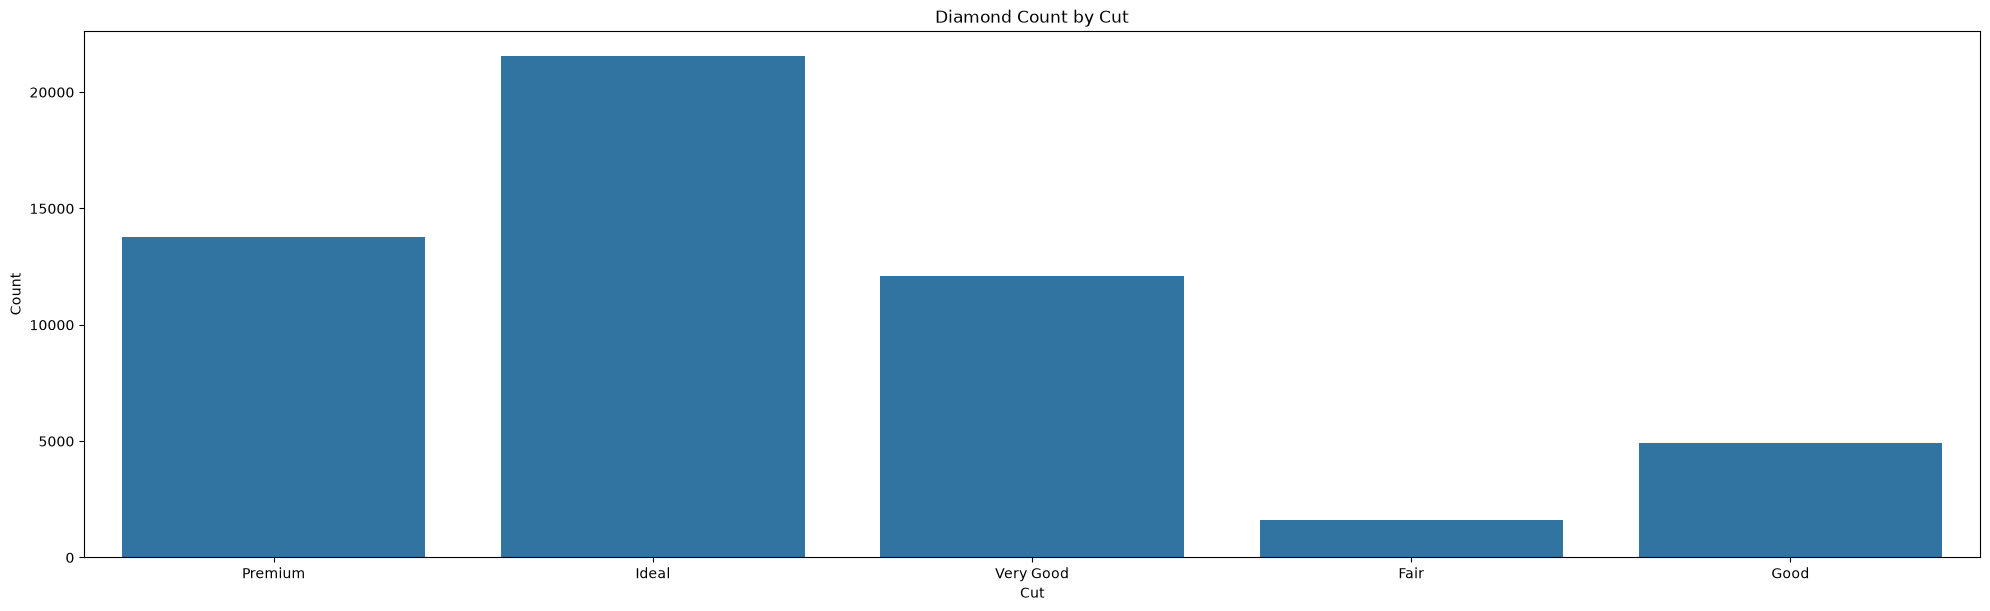

In [40]:

# Graph ka size set kar rahe hain
plt.figure(figsize=(20, 6))

# Har cut category ke diamonds ki counting dikha rahe hain
sns.countplot(data=df, x='cut')

# Graph ki spacing adjust kar rahe hain
plt.tight_layout()

# Graph ka title set kar rahe hain
plt.title('Diamond Count by Cut')

# X-axis aur Y-axis ke labels set kar rahe hain
plt.xlabel('Cut')
plt.ylabel('Count')

# Graph display kar rahe hain
plt.show()
